# 69 — Validated BOB availability overview

Run 61–68 first. Read only completed QC-schema-2 exports from the configured external FAIR tree. A missing/unexecuted product is **unknown**, not zero historical availability. Default behaviour blocks incomplete overviews; an explicit partial mode marks incomplete rows and the figure.

Presence means at least one finite nonsentinel measurement within the product's documented expected-date bounds. SSAM/DATA are unioned by recorded day; measurements and source alternatives are never summed. The main figure ends at 1 December 1991 (exclusive); full-range table entries retain the isolated 1992 SSAM records. Radio maps are metadata snapshots and remain separate.


## Review of the supplied saved execution

The supplied overview notebook has not been executed. MUDFLOW is also unexecuted, so a complete overview should remain blocked until its products exist. The revised overview additionally requires QC-schema-2 completion markers, preventing old unreviewed coverage products from being mistaken for the new outputs.

This describes the supplied version, not a new execution. Revised code cells have been cleared so stale results cannot be mistaken for current outputs. The original executed notebook is backed up.


In [1]:
from pathlib import Path
import os, sys, json, hashlib, re
from datetime import datetime, timezone
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
# Support launching Jupyter from either the repository or 10_conversion.
HERE = Path.cwd().resolve()
CONVERSION = HERE if (HERE / 'pinatubo_steps').is_dir() else HERE / '10_conversion'
if not (CONVERSION / 'pinatubo_steps').is_dir():
    raise RuntimeError('Launch Jupyter from the repository root or 10_conversion.')
if str(CONVERSION) not in sys.path: sys.path.insert(0, str(CONVERSION))
from pinatubo_steps.config import pipeline_paths, load_conversion_config
CONFIG_FILE = os.environ.get('PINATUBO_CONVERSION_CONFIG')  # None selects shared default
PATHS = pipeline_paths(config_file=CONFIG_FILE)
CONFIG = load_conversion_config(CONFIG_FILE)
BOB_CONFIG = CONFIG.get('legacy_bob', {})
BOB_ROOT = Path(PATHS['LEGACY_TOP']) / 'BOB'
BOB_OUTPUT = Path(PATHS['FAIR_TOP']) / 'BOB'
NOTEBOOK_NAME = '69_bob_coverage_and_review.ipynb'
OVERWRITE = True  # Set True only to deliberately replace this notebook's derived products.
print('Inputs:', BOB_ROOT, '\nOutputs:', BOB_OUTPUT)


Inputs: /Users/thompsong/Library/CloudStorage/Box-Box/thompsong/DATA/pinatubo1991/LEGACY/BOB 
Outputs: /Users/thompsong/work/Pinatubo1991Processing/converted/FAIR/BOB


In [2]:
PRODUCTS={'SSAM':['ssam','ssam_data'],'RSAM':['rsam'],'RSAM EVNT':['rsam_events'],
          'TILT':['tilt'],'MUDFLOW':['mudflow'],'RAIN':['rain'],'COSPEC':['cospec'],'COUNTS':['counts']}
START,END=pd.Timestamp('1991-04-01'),pd.Timestamp('1991-12-01')
ALLOW_PARTIAL=False  # True is for explicitly labelled diagnostic previews only.


## Validate inputs and assemble daily presence

Completion markers and run IDs protect against interrupted/mixed exports. Older outputs must be regenerated; parser success alone does not establish trustworthy dates. This uses the revised per-product date-review flags. Source product paths and hashes are retained in the overview report.


In [3]:
def assemble_coverage(root, products, start, end, *, allow_partial=False):
    root=Path(root);start=pd.Timestamp(start);end=pd.Timestamp(end)
    if end<=start:raise ValueError('Overview end must exceed start')
    coverage={};table=[];reviews=[];missing=[];inputs=[]
    for label,names in products.items():
        chunks=[];available=[];flags=0
        for name in names:
            folder=root/name
            required=[folder/n for n in ['daily_coverage.csv','review.json','export_status.json']]
            if not all(p.exists() for p in required):
                missing.append(name+': missing outputs or QC completion marker');continue
            review=json.loads(required[1].read_text());status=json.loads(required[2].read_text())
            if status.get('complete') is not True or status.get('qc_schema_version')!=2 or review.get('run_id')!=status.get('run_id'):
                missing.append(name+': incomplete, mixed-run or older QC schema; rerun its notebook');continue
            frame=pd.read_csv(required[0],parse_dates=['recorded_date'])
            if not {'recorded_date','series','unique_timestamps'}.issubset(frame.columns):
                raise ValueError(f'Unexpected daily-coverage schema in {required[0]}')
            if frame.recorded_date.isna().any():raise ValueError('Invalid dates in derived coverage')
            chunks.append(frame);available.append(name);reviews.append(review)
            flags+=sum(int(review.get(k,0)) for k in ['parser_errors','invalid_times','outside_expected_dates','duplicate_timestamp_rows'])
            inputs.extend(dict(path=str(p),sha256=hashlib.sha256(p.read_bytes()).hexdigest()) for p in required)
        days=pd.DatetimeIndex(pd.concat(chunks,ignore_index=True).recorded_date.unique()).sort_values() if chunks else pd.DatetimeIndex([])
        coverage[label]=days
        complete=len(available)==len(names)
        table.append(dict(data_type=label,status='complete_products' if complete else 'INCOMPLETE_PRODUCTS',
            first=days.min() if len(days) else pd.NaT,last=days.max() if len(days) else pd.NaT,
            observed_days=len(days) if complete else np.nan,available_product_days=len(days),
            days_in_main_figure=int(((days>=start)&(days<end)).sum()) if complete else np.nan,
            outside_main_figure=int(((days<start)|(days>=end)).sum()) if complete else np.nan,
            available_products=';'.join(available),required_products=';'.join(names),review_flag_count=flags))
    if missing and not allow_partial:raise FileNotFoundError('Overview blocked; missing/unreviewed outputs:\n'+'\n'.join(missing))
    return coverage,pd.DataFrame(table),reviews,missing,inputs


In [4]:
coverage,summary,reviews,missing,inputs=assemble_coverage(BOB_OUTPUT,PRODUCTS,START,END,allow_partial=ALLOW_PARTIAL)
display(summary);display(pd.DataFrame(reviews))
for issue in missing:print('INCOMPLETE:',issue)
target=BOB_OUTPUT/'overview'
for name in ['coverage_by_data_type.csv','bob_coverage_1991.png','review.json']:
    if (target/name).exists() and not OVERWRITE:raise FileExistsError(target/name)
target.mkdir(parents=True,exist_ok=True)
summary.to_csv(target/'coverage_by_data_type.csv',index=False)



,data_type,status,first,last,observed_days,available_product_days,days_in_main_figure,outside_main_figure,available_products,required_products,review_flag_count
0,SSAM,complete_products,1991-06-01,1992-03-21,135,135,134,1,ssam;ssam_data,ssam;ssam_data,6353
1,RSAM,complete_products,1991-04-20,1991-11-22,205,205,205,0,rsam,rsam,52704
2,RSAM EVNT,complete_products,1991-04-20,1991-11-22,205,205,205,0,rsam_events,rsam_events,0
3,TILT,complete_products,1991-06-01,1991-06-13,13,13,13,0,tilt,tilt,0
4,MUDFLOW,complete_products,1991-07-17,1991-11-22,121,121,121,0,mudflow,mudflow,221
5,RAIN,complete_products,1991-07-16,1991-11-22,120,120,120,0,rain,rain,254
6,COSPEC,complete_products,1991-05-13,1991-10-03,17,17,17,0,cospec,cospec,2
7,COUNTS,complete_products,1991-04-30,1991-11-06,176,176,176,0,counts,counts,12


,qc_schema_version,run_id,generated_utc,product,rows,parser_errors,invalid_times,outside_expected_dates,auxiliary_source_rows,duplicate_timestamp_rows,ambiguous_timestamps,expected_dates,status,coverage_meaning,notes
0,2,20261112T155217946029Z,2026-11-12T15:52:17.946014+00:00,ssam,635862,0,0,0,11489,5999,2996,"{'start': '1991-01-01 00:00:00', 'end_exclusiv...",review_required,A finite nonsentinel value with valid recorded...,Source-documented SSAM frequency bands are ing...
1,2,20261112T155224698258Z,2026-11-12T15:52:24.698250+00:00,ssam_data,41632,0,0,0,0,354,177,"{'start': '1991-01-01 00:00:00', 'end_exclusiv...",review_required,A finite nonsentinel value with valid recorded...,Source-documented SSAM frequency bands are ing...
2,2,20261112T155226754990Z,2026-11-12T15:52:26.754983+00:00,rsam,946224,0,0,52704,105264,0,0,"{'start': '1991-01-01 00:00:00', 'end_exclusiv...",review_required,A finite nonsentinel value with valid recorded...,RSAM is a sampled amplitude measure; EVNT is t...
3,2,20261112T155230517388Z,2026-11-12T15:52:30.517381+00:00,rsam_events,473040,0,0,0,0,0,0,"{'start': '1991-01-01 00:00:00', 'end_exclusiv...",no_automatic_flags,A finite nonsentinel value with valid recorded...,RSAM is a sampled amplitude measure; EVNT is t...
4,2,20261112T170229007221Z,2026-11-12T17:02:29.007215+00:00,tilt,473040,0,0,0,0,0,0,"{'start': '1991-01-01 00:00:00', 'end_exclusiv...",no_automatic_flags,A finite nonsentinel value with valid recorded...,"TILT uses the annual RSAM storage format, but ..."
5,2,20261112T170328510047Z,2026-11-12T17:03:28.510038+00:00,mudflow,33694,3,0,0,0,218,104,"{'start': '1991-01-01 00:00:00', 'end_exclusiv...",review_required,A finite nonsentinel value with valid recorded...,Read three positional values per measurement. ...
6,2,20261112T170304707691Z,2026-11-12T17:03:04.707684+00:00,rain,23914,1,0,0,0,253,100,"{'start': '1991-01-01 00:00:00', 'end_exclusiv...",review_required,A finite nonsentinel value with valid recorded...,"Compile all daily DAT records into one table, ..."
7,2,20261112T170349461709Z,2026-11-12T17:03:49.461706+00:00,cospec,18,0,0,0,0,2,1,"{'start': '1991-01-01 00:00:00', 'end_exclusiv...",review_required,A finite nonsentinel value with valid recorded...,The legacy file contains sparse SO₂ measuremen...
8,2,20261112T170413239472Z,2026-11-12T17:04:13.239462+00:00,counts,5189,3,1,4,0,4,2,"{'start': '1991-01-01 00:00:00', 'end_exclusiv...",review_required,A finite nonsentinel value with valid recorded...,CAB_CNT and CAB_HR are overlapping alternative...


## Network-wide observed-day figure

One touching rectangle per observed day, across original source series. Blank periods are gaps among the available records, not proof of instrument downtime. Sparse COSPEC measurements stay sparse. An incomplete product row is explicitly marked; its day count remains unknown.


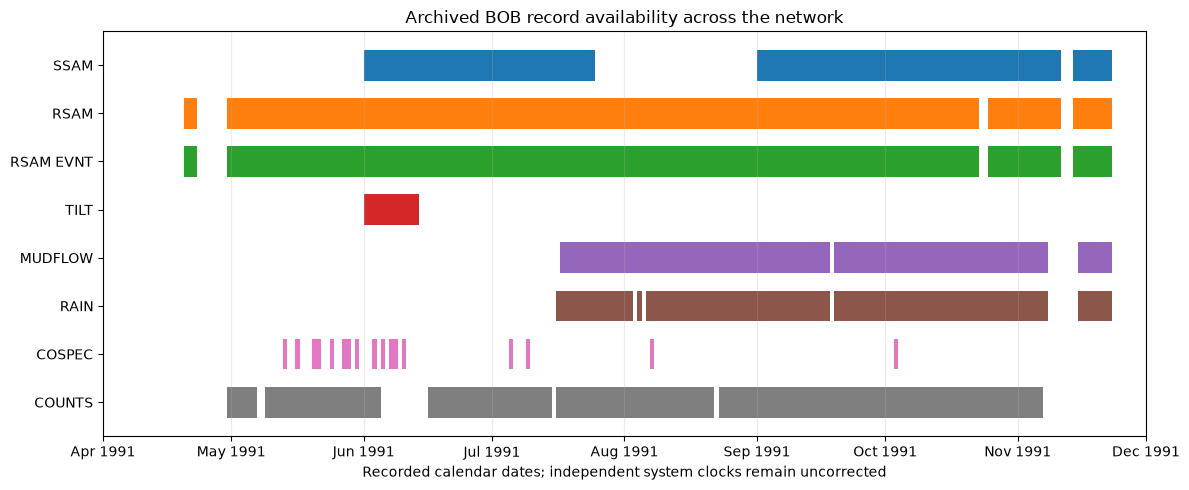

,source_file,snapshot_date,rows,interpreted_table_sha256,matching_source_snapshots
0,SEIS_MAP.CUR,1991-07-08,10,d47f559a8184485ced0009f44f90f0ceb47bc33219cd82...,2
1,SEIS_MAP.OLD,1991-05-14,9,e6a90581906db7dce8c447d9a36caa3d82e50cef3f97f2...,1
2,SEIS_MAP.OLD,1991-06-27,9,5e89cb1816ae3b6de4c1a46cf65b547d71bdf619691d68...,1
3,SEIS_MAP.OLD,1991-07-08,10,d47f559a8184485ced0009f44f90f0ceb47bc33219cd82...,2


In [5]:
import matplotlib.dates as mdates
fig,ax=plt.subplots(figsize=(12,5))
labels=[]
for i,(label,days) in enumerate(coverage.items()):
    selected=days[(days>=START)&(days<END)]
    complete=summary.loc[summary.data_type.eq(label),'status'].iloc[0]=='complete_products'
    ax.broken_barh([(mdates.date2num(day),1) for day in selected],(i-.32,.64),facecolors=f'C{i%10}',alpha=1 if complete else .4)
    labels.append(label if complete else label+' [INCOMPLETE INPUTS]')
ax.set_yticks(range(len(labels)),labels);ax.invert_yaxis();ax.set_xlim(START,END)
ax.xaxis.set_major_locator(mdates.MonthLocator());ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.set(title=('PARTIAL — ' if missing else '')+'Archived BOB record availability across the network',xlabel='Recorded calendar dates; independent system clocks remain uncorrected')
ax.grid(axis='x',alpha=.25);fig.tight_layout();fig.savefig(target/'bob_coverage_1991.png',dpi=220)
plt.show();plt.close(fig)
(target/'review.json').write_text(json.dumps(dict(qc_schema_version=2,generated_utc=datetime.now(timezone.utc).isoformat(),
    missing_outputs=missing,reviews=reviews,derived_inputs=inputs,
    time_policy='Recorded labels; no cross-system synchronization or drift correction',
    coverage='Union of finite-nonsentinel observed days within expected dates; not uptime',
    main_start=str(START),main_end_exclusive=str(END)),indent=2,default=str)+'\n')
radio=BOB_OUTPUT/'radio'/'snapshot_equivalence.csv'
if radio.exists():display(pd.read_csv(radio))
else:print('Run step 68 for the separate telemetry snapshot comparison.')



## Review before manuscript use

- Confirm source duplicates/auxiliary copies before identifying physical stations or summing measurements.
- SSAM band limits are documented and ingested. Averaging duration, amplitude scaling and label phase remain separate questions.
- Date outliers are preserved for review; no date repair is inferred. Expected-date exclusions are reported by each product.
- Independent RSAM/EVNT, SSAM, rain, tilt and helicorder clocks require separate evidence before cross-system alignment.
- Generate the overview only after all product completion markers exist. Full conversion/QC does not by itself establish calibrated scientific measurements.

